In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from sklearn.model_selection import ParameterGrid
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

BASE_DIR = "/content/drive/MyDrive/NLP project"
MODEL_NAME = "mental/mental-roberta-base"

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
# 1. Open huggingface.co/mental/mental-roberta-base and accept the terms (once)
# 2. Create a token at huggingface.co/settings/tokens (type "Read") and paste it below
from huggingface_hub import login
login()

In [ ]:
train = pd.read_csv(f"{BASE_DIR}/train.csv")
val = pd.read_csv(f"{BASE_DIR}/val.csv")
test = pd.read_csv(f"{BASE_DIR}/test.csv")

classes = sorted(train["status"].unique())
class_to_num = {c: i for i, c in enumerate(classes)}
y_train = train["status"].map(class_to_num).values
y_val = val["status"].map(class_to_num).values
y_test = test["status"].map(class_to_num).values

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

lengths = np.array([len(ids) for ids in tokenizer(train["statement"].tolist())["input_ids"]])
print(f"Median tokens: {np.median(lengths):.0f} | p95: {np.percentile(lengths, 95):.0f}")
print(f"Truncated at 256: {(lengths > 256).mean():.1%} | at 512: {(lengths > 512).mean():.1%}")

config.json:   0%|          | 0.00/682 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (739 > 512). Running this sequence through the model will result in indexing errors


Median tokens: 74 | p95: 454
Truncated at 256: 14.9% | at 512: 3.9%


In [ ]:
MAX_LEN = 512
HEAD = 128      # keep the first 128 and last 384 tokens of long posts (Sun et al., 2019)

def make_dataset(df, y):
    enc = tokenizer(df["statement"].tolist(), truncation=False)
    data = []
    for ids, l in zip(enc["input_ids"], y):
        if len(ids) > MAX_LEN:
            ids = ids[:HEAD] + ids[-(MAX_LEN - HEAD):]   # still starts with <s> and ends with </s>
        data.append({"input_ids": ids, "attention_mask": [1] * len(ids), "labels": int(l)})
    return data

train_data, val_data = make_dataset(train, y_train), make_dataset(val, y_val)
collator = DataCollatorWithPadding(tokenizer)   # pads each batch to its longest text

weights = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_train)
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))

In [ ]:
from tqdm.auto import tqdm

EPOCHS = 3
PATIENCE = 1

@torch.no_grad()
def predict(model, data):
    model.eval()
    preds = []
    for batch in DataLoader(data, batch_size=64, collate_fn=collator):
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        with torch.autocast("cuda", dtype=torch.float16):
            preds.append(model(**batch).logits.argmax(1).cpu())
    return torch.cat(preds).numpy()

@torch.no_grad()
def predict_logits(model, data):
    model.eval()
    out = []
    for batch in DataLoader(data, batch_size=64, collate_fn=collator):
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(**batch).logits.float().cpu())
    return torch.cat(out)

def train_model(lr, batch_size=16, warmup=0.06, weight_decay=0.01):
    torch.manual_seed(42)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(classes)).to(device)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collator)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = EPOCHS * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(warmup * total_steps), total_steps)
    scaler = torch.amp.GradScaler()
    y_val_t = torch.tensor(y_val).to(device)

    best_f1, best_acc, best_state, wait, history = -1, 0, None, 0, []
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct = 0, 0
        for batch in tqdm(loader, desc=f"epoch {epoch}", leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")
            optimizer.zero_grad()
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()

        val_logits = predict_logits(model, val_data)
        val_loss = loss_fn(val_logits.to(device), y_val_t).item()
        pred = val_logits.argmax(1).numpy()
        acc = accuracy_score(y_val, pred)
        f1 = f1_score(y_val, pred, average="macro")

        history.append({"epoch": epoch,
                        "train_loss": total_loss / len(train_data), "train_accuracy": correct / len(train_data),
                        "val_loss": val_loss, "val_accuracy": acc, "val_macro_f1": f1})
        print(f"  epoch {epoch}: train_loss={total_loss / len(train_data):.4f} | val_loss={val_loss:.4f} | "
              f"train_acc={correct / len(train_data):.4f} | val_acc={acc:.4f} | macro-F1={f1:.4f} | "
              f"{time.time() - start:.0f}s")

        if f1 > best_f1:
            best_f1, best_acc, wait = f1, acc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    train_time = time.time() - start
    del model, optimizer
    torch.cuda.empty_cache()
    return best_state, best_acc, best_f1, train_time, history

In [ ]:
param_grid = {
    "lr": [2e-5],
    "batch_size": [16],
}

grid = list(ParameterGrid(param_grid))
results = []
best_f1 = -1

for i, params in enumerate(grid, 1):
    print(f"[{i}/{len(grid)}] {params}")
    state, acc, f1, train_time, history = train_model(**params)
    results.append({"params": params, "val_accuracy": acc, "val_macro_f1": f1, "train_time_s": train_time})
    print(f"  -> best epoch: acc={acc:.4f} | macro-F1={f1:.4f} | {train_time:.0f}s\n")

    if f1 > best_f1:
        best_f1, best_state, best_params, best_history, best_train_time = f1, state, params, history, train_time

[1/1] {'batch_size': 16, 'lr': 2e-05}


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: mental/mental-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1:   0%|          | 0/2233 [00:00<?, ?it/s]

... (3 outputs left out)

epoch 2:   0%|          | 0/2233 [00:00<?, ?it/s]

  epoch 2: train_loss=0.3780 | val_loss=0.6591 | train_acc=0.8601 | val_acc=0.8439 | macro-F1=0.8135 | 1034s


epoch 3:   0%|          | 0/2233 [00:00<?, ?it/s]

  epoch 3: train_loss=0.2531 | val_loss=0.6748 | train_acc=0.8951 | val_acc=0.8488 | macro-F1=0.8250 | 1552s
  -> best epoch: acc=0.8488 | macro-F1=0.8250 | 1552s



In [ ]:
results_df = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
print("Best:", best_params)
results_df

Best: {'batch_size': 16, 'lr': 2e-05}


,params,val_accuracy,val_macro_f1,train_time_s
0,"{'batch_size': 16, 'lr': 2e-05}",0.848817,0.825002,1551.636753


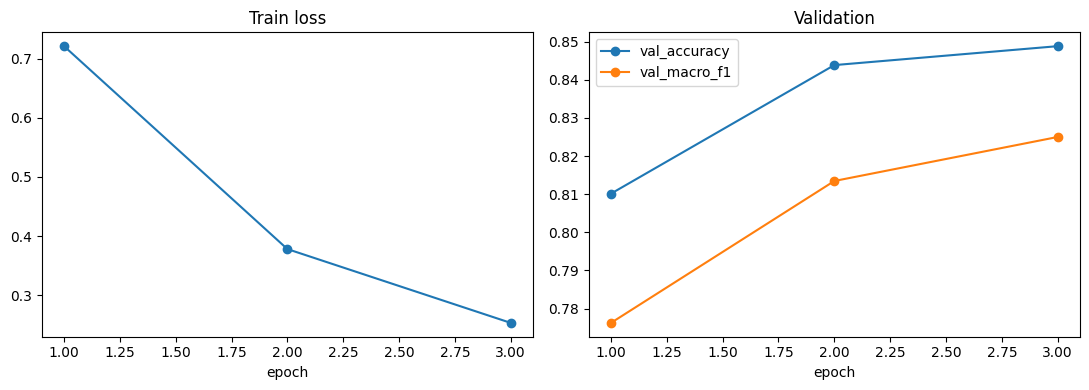

In [ ]:
h = pd.DataFrame(best_history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
h.plot(x="epoch", y="train_loss", ax=axes[0], marker="o", title="Train loss", legend=False)
h.plot(x="epoch", y=["val_accuracy", "val_macro_f1"], ax=axes[1], marker="o", title="Validation")
plt.tight_layout()
plt.show()

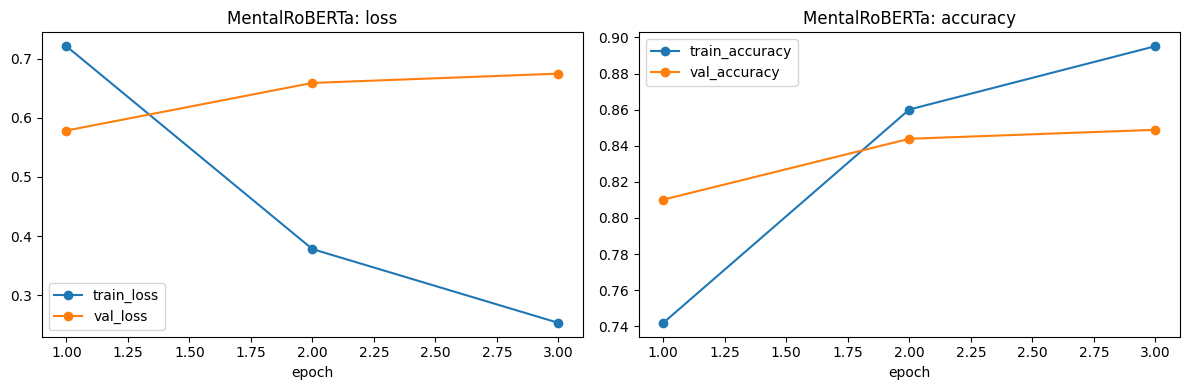

In [ ]:
h = pd.DataFrame(best_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], marker="o", title="MentalRoBERTa: loss")
h.plot(x="epoch", y=["train_accuracy", "val_accuracy"], ax=axes[1], marker="o", title="MentalRoBERTa: accuracy")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: mental/mental-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Train: 1551.6s | Inference: 32.26s
                      precision    recall  f1-score   support

             Anxiety      0.891     0.900     0.895       542
             Bipolar      0.854     0.872     0.863       375
          Depression      0.850     0.727     0.784      2261
              Normal      0.966     0.957     0.962      2403
Personality disorder      0.784     0.731     0.757       134
              Stress      0.743     0.817     0.778       344
            Suicidal      0.700     0.837     0.762      1595

            accuracy                          0.846      7654
           macro avg      0.827     0.834     0.829      7654
        weighted avg      0.852     0.846     0.846      7654



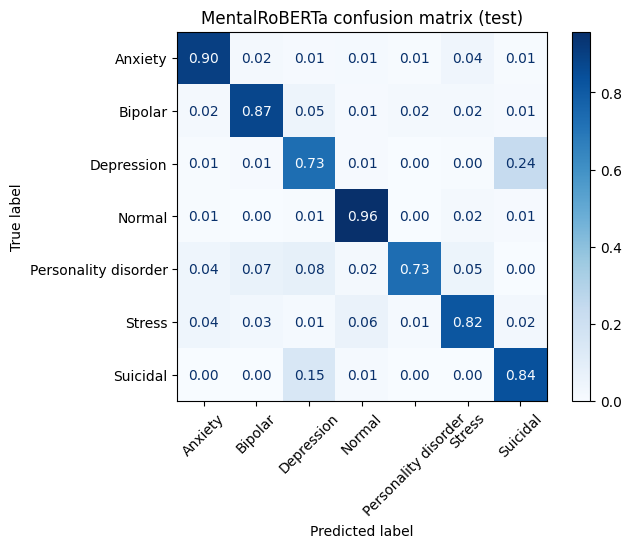

In [ ]:
best_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(classes))
best_model.load_state_dict(best_state)
best_model.to(device)

start = time.time()
test_data = make_dataset(test, y_test)          # include tokenization, like the other models
y_pred_num = predict(best_model, test_data)
inference_time = time.time() - start

y_pred = np.array(classes)[y_pred_num]

print(f"Train: {best_train_time:.1f}s | Inference: {inference_time:.2f}s")
print(classification_report(test["status"], y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(test["status"], y_pred, normalize="true",
                                        xticks_rotation=45, values_format=".2f", cmap="Blues")
plt.title("MentalRoBERTa confusion matrix (test)")
plt.show()

In [ ]:
test_probs = torch.softmax(predict_logits(best_model, test_data), dim=1).numpy()
pd.DataFrame(test_probs, columns=classes).assign(id=test["id"].values).to_csv(f"{BASE_DIR}/mentalroberta_scores.csv", index=False)

In [ ]:
pd.DataFrame({"id": test["id"], "true": test["status"], "pred": y_pred}).to_csv(f"{BASE_DIR}/mentalroberta_preds.csv", index=False)

pd.DataFrame([{
    "model": "mentalroberta",
    "accuracy": accuracy_score(test["status"], y_pred),
    "macro_f1": f1_score(test["status"], y_pred, average="macro"),
    "weighted_f1": f1_score(test["status"], y_pred, average="weighted"),
    "train_time_s": best_train_time,
    "inference_time_s": inference_time,
}]).to_csv(f"{BASE_DIR}/mentalroberta_metrics.csv", index=False)

In [ ]:
best_model.config.id2label = {i: c for i, c in enumerate(classes)}
best_model.config.label2id = {c: i for i, c in enumerate(classes)}
best_model.save_pretrained(f"{BASE_DIR}/mentalroberta_model")
tokenizer.save_pretrained(f"{BASE_DIR}/mentalroberta_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/NLP project/mentalroberta_model/tokenizer_config.json',
 '/content/drive/MyDrive/NLP project/mentalroberta_model/tokenizer.json')

In [ ]:
# Cell 8: flush Drive and disconnect
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()